# Waste Segregation Assistent
## Problem Statement

Incorrect waste segregation leads to recycling inefficiency and environmental damage. People often do not know whether waste belongs to dry, wet, recyclable, or hazardous categories.

## Dataset

Each category has 4 classes. For Biodegradable class:
paper, leaf, food, wood

For Non-Biodegradable class:
waste, plastic bags, plastic bottles, metal cans

To do:
Train a classifier model to predict whether the image belongs to the Biodegradable or Non-Biodegradable class.
You can use transfer learning or make your own Neural Network for the same.

## Importing nessesary libraries and dataset

In [4]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [5]:
%pip install -U numpy pandas matplotlib seaborn opencv-python pillow tqdm scikit-learn
%pip install -U torch torchvision torchaudio
%pip install -U ultralytics  # YOLOv8
%pip install -U kaggle

import pandas as pd
print("pandas version:", pd.__version__)

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
pandas version: 3.0.1


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm import tqdm

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Torch
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [7]:
import os

DATA_DIR = "../data/raw/train"  # adjust if needed

main_classes = ["biodegradable", "non_biodegradable"]

In [8]:
categories = os.listdir(DATA_DIR)
print("Categories:", categories)

Categories: ['.DS_Store', 'non_biodegradable', 'biodegradable']


In [9]:
from collections import defaultdict

data_stats = defaultdict(dict)

for main_class in main_classes:
    main_path = os.path.join(DATA_DIR, main_class)
    
    total = 0
    
    for sub_class in os.listdir(main_path):
        # Skip hidden files like .DS_Store and any non-directory entries
        if sub_class.startswith('.'):
            continue
        sub_path = os.path.join(main_path, sub_class)
        if not os.path.isdir(sub_path):
            continue
        # Count only non-hidden items inside the sub-folder
        count = len([f for f in os.listdir(sub_path) if not f.startswith('.')])
        
        data_stats[main_class][sub_class] = count
        total += count
    
    data_stats[main_class]["TOTAL"] = total

data_stats

defaultdict(dict,
            {'biodegradable': {'food_waste': 10066,
              'leaf_waste': 1179,
              'paper_waste': 860,
              'wood_waste': 593,
              'TOTAL': 12698},
             'non_biodegradable': {'metal_cans': 670,
              'plastic_bottles': 417,
              'ewaste': 180,
              'plastic_bags': 200,
              'TOTAL': 1467}})

In [10]:
for main_class, sub_data in data_stats.items():
    print(f"\n🔹 {main_class.upper()}")
    for sub_class, count in sub_data.items():
        print(f"{sub_class}: {count}")


🔹 BIODEGRADABLE
food_waste: 10066
leaf_waste: 1179
paper_waste: 860
wood_waste: 593
TOTAL: 12698

🔹 NON_BIODEGRADABLE
metal_cans: 670
plastic_bottles: 417
ewaste: 180
plastic_bags: 200
TOTAL: 1467


### Checking for class Imbalance

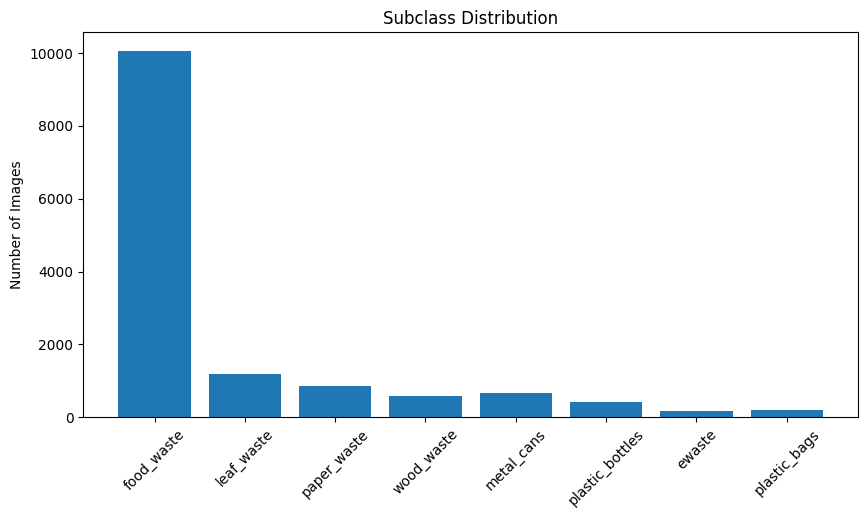

In [11]:
import matplotlib.pyplot as plt

labels = []
counts = []

for main_class in data_stats:
    for sub_class in data_stats[main_class]:
        if sub_class != "TOTAL":
            labels.append(sub_class)
            counts.append(data_stats[main_class][sub_class])

plt.figure(figsize=(10,5))
plt.bar(labels, counts)
plt.xticks(rotation=45)
plt.title("Subclass Distribution")
plt.ylabel("Number of Images")
plt.show()

The dataset is highly imbalanced both at class and subclass levels, which required techniques like class weighting, augmentation, and stratified sampling to ensure fair learning.

### Sample data checking

In [12]:
from PIL import Image
import random

def show_samples(main_class, sub_class, n=5):
    path = os.path.join(DATA_DIR, main_class, sub_class)
    images = random.sample(os.listdir(path), n)
    
    plt.figure(figsize=(15,5))
    
    for i, img_name in enumerate(images):
        img_path = os.path.join(path, img_name)
        img = Image.open(img_path)
        
        plt.subplot(1, n, i+1)
        plt.imshow(img)
        plt.title(f"{main_class}\n{sub_class}")
        plt.axis("off")
    
    plt.show()

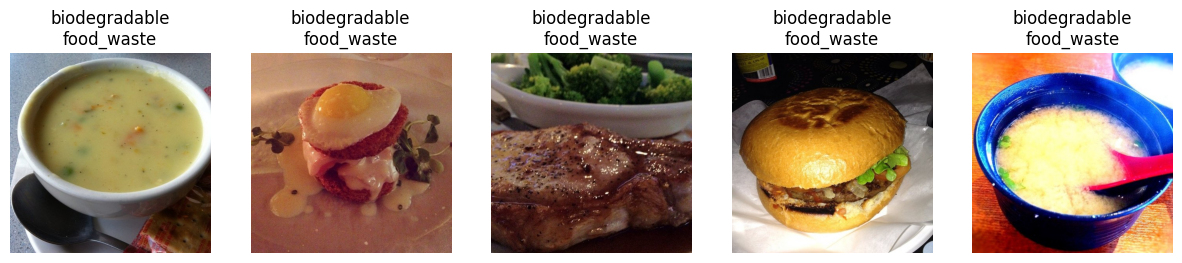

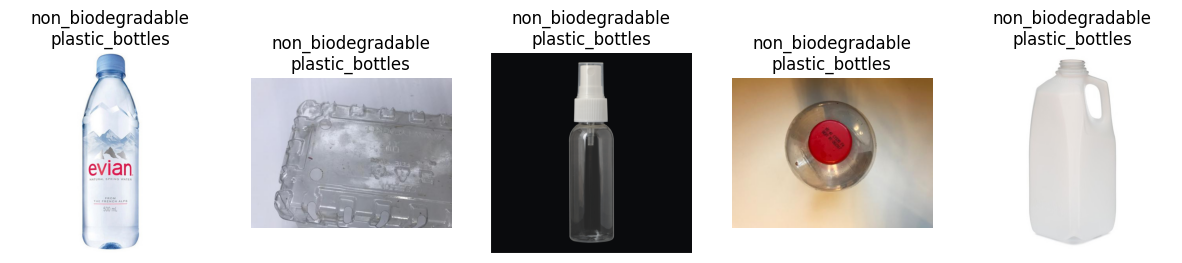

In [13]:
show_samples("biodegradable", "food_waste")
show_samples("non_biodegradable", "plastic_bottles")

## Data Pipeline

### Step 1: Create Label Mapping (Binary)

In [14]:
label_map = {
    "biodegradable": 0,
    "non_biodegradable": 1
}

### Step 2: Create Image Paths + Labels

In [15]:
import os
import pandas as pd

DATA_DIR = "../data/raw/train"

label_map = {
    "biodegradable": 0,
    "non_biodegradable": 1
}

data = []

# Loop through main classes explicitly
for main_class in ["biodegradable", "non_biodegradable"]:
    
    main_path = os.path.join(DATA_DIR, main_class)
    
    if not os.path.isdir(main_path):
        print(f"Skipping missing folder: {main_path}")
        continue
    
    # Loop through subclasses
    for sub_class in os.listdir(main_path):
        sub_path = os.path.join(main_path, sub_class)
        
        if not os.path.isdir(sub_path):
            continue
        
        # Loop through images
        for img_name in os.listdir(sub_path):
            
            # Skip hidden/system files
            if img_name.startswith("."):
                continue
            
            img_path = os.path.join(sub_path, img_name)
            
            data.append({
                "image_path": img_path,
                "label": label_map[main_class],
                "main_class": main_class,
                "sub_class": sub_class
            })

df = pd.DataFrame(data)

print("Total samples:", len(df))
df.head()

Total samples: 14165


,image_path,label,main_class,sub_class
0,../data/raw/train/biodegradable/food_waste/10_...,0,biodegradable,food_waste
1,../data/raw/train/biodegradable/food_waste/2_1...,0,biodegradable,food_waste
2,../data/raw/train/biodegradable/food_waste/9_9...,0,biodegradable,food_waste
3,../data/raw/train/biodegradable/food_waste/8_5...,0,biodegradable,food_waste
4,../data/raw/train/biodegradable/food_waste/5_1...,0,biodegradable,food_waste


### Step:3 Check class Distribution (Binary)

In [16]:
df['label'].value_counts()

label
0    12698
1     1467
Name: count, dtype: int64

### Step 4: Train val Test Split

In [17]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],  # VERY IMPORTANT
    random_state=42
)

### Step 5: Define Transformations

In [18]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    
    # 🔥 Augmentation (VERY IMPORTANT)
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])


val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

### Step 6: Custom Dataset Class

In [19]:
from torch.utils.data import Dataset
from PIL import Image

class WasteDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['image_path']
        label = self.df.iloc[idx]['label']
        
        try:
            image = Image.open(img_path).convert("RGB")
        except Exception as e:
            # 🔥 Skip bad image by loading a random valid one
            new_idx = np.random.randint(0, len(self.df))
            return self.__getitem__(new_idx)
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

### Step7:  Create Dataloaders

In [20]:
from torch.utils.data import DataLoader

train_dataset = WasteDataset(train_df, transform=train_transforms)
val_dataset = WasteDataset(val_df, transform=val_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

### Step 8: Handle Class IMbalance

In [21]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(df['label']),
    y=df['label']
)

class_weights = torch.tensor(class_weights, dtype=torch.float)
class_weights

tensor([0.5578, 4.8279])

Due to severe class imbalance, I used weighted loss functions to prevent bias towards the majority class.

## Build the Model: Pretrained ResNet18

Due to limited and imbalanced data, I used transfer learning with ResNet18 to leverage pretrained feature representations, improving generalization and training efficiency.

### Step 1 : Load Pretrained model

In [22]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained ResNet18
model = models.resnet18(pretrained=True)

/opt/miniconda3/envs/my_py311/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/miniconda3/envs/my_py311/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


### Stp 2: Modify final layer
This model has 1000 layers, we need only 2

In [23]:
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 2)

model = model.to(device)

### Step 3: Freeze early layers

In [24]:
for param in model.parameters():
    param.requires_grad = False

# Only train final layer
for param in model.fc.parameters():
    param.requires_grad = True

### Step 4: LOss + Optimizers

In [25]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

### Step 5: Training

In [26]:
from tqdm import tqdm

def train_model(model, train_loader, val_loader, epochs=5):
    
    best_val_acc = 0
    
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        
        # -------- TRAIN --------
        model.train()
        train_loss = 0
        correct = 0
        
        for images, labels in tqdm(train_loader):
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
        
        train_acc = correct / len(train_loader.dataset)
        
        # -------- VALIDATION --------
        model.eval()
        val_loss = 0
        correct = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
        
        val_acc = correct / len(val_loader.dataset)
        
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
        
        # -------- SAVE BEST MODEL --------
        if val_acc > best_val_acc:
            best_val_acc = val_acc
    
    os.makedirs("../models", exist_ok=True)  # ensure folder exists
    torch.save(model.state_dict(), "../models/best.pt")
    
    print("✅ Best model saved!")

In [27]:
train_model(model, train_loader, val_loader, epochs=5)


Epoch 1/5


  8%|▊         | 28/355 [00:16<03:10,  1.72it/s]/opt/miniconda3/envs/my_py311/lib/python3.11/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 355/355 [03:40<00:00,  1.61it/s]


Train Loss: 75.9753 | Train Acc: 0.9187
Val Loss: 10.5270 | Val Acc: 0.9403

Epoch 2/5


100%|██████████| 355/355 [04:39<00:00,  1.27it/s]


Train Loss: 46.8233 | Train Acc: 0.9513
Val Loss: 9.6387 | Val Acc: 0.9414

Epoch 3/5


...

Train Loss: 42.9434 | Train Acc: 0.9544
Val Loss: 7.2224 | Val Acc: 0.9636

Epoch 4/5


100%|██████████| 355/355 [04:48<00:00,  1.23it/s]


Train Loss: 40.4959 | Train Acc: 0.9567
Val Loss: 6.9090 | Val Acc: 0.9679

Epoch 5/5


100%|██████████| 355/355 [13:57<00:00,  2.36s/it]    


Train Loss: 39.5406 | Train Acc: 0.9581
Val Loss: 7.0930 | Val Acc: 0.9633
✅ Best model saved!


## Evaluation

### Step 1: Predictions

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

def evaluate_model(model, loader):
    model.eval()
    
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    return np.array(all_labels), np.array(all_preds)

In [29]:
y_true, y_pred = evaluate_model(model, val_loader)

### Step 2: Classification Report

In [30]:
print(classification_report(y_true, y_pred, target_names=["Biodegradable", "Non-Biodegradable"]))

                   precision    recall  f1-score   support

    Biodegradable       1.00      0.96      0.98      2540
Non-Biodegradable       0.74      0.99      0.85       293

         accuracy                           0.96      2833
        macro avg       0.87      0.97      0.91      2833
     weighted avg       0.97      0.96      0.97      2833



### Step 3: Confusion Matrix

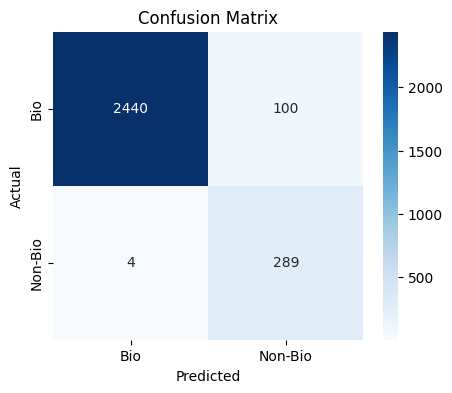

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Bio", "Non-Bio"],
            yticklabels=["Bio", "Non-Bio"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Step 4: Failure Analysis (Missclassification)

In [32]:
def show_misclassified(model, loader, dataset, num_images=5):
    model.eval()
    
    shown = 0
    
    with torch.no_grad():
        for i, (images, labels) in enumerate(loader):
            images = images.to(device)
            
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            for j in range(len(images)):
                if preds[j] != labels[j]:
                    
                    img = images[j].cpu().permute(1,2,0).numpy()
                    
                    plt.imshow(img)
                    plt.title(f"Pred: {preds[j].item()} | True: {labels[j].item()}")
                    plt.axis("off")
                    plt.show()
                    
                    shown += 1
                    
                    if shown >= num_images:
                        return

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.6051416].


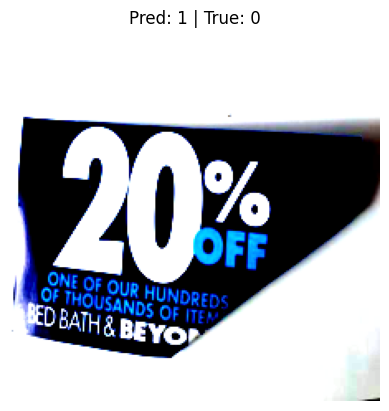

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..2.5877128].


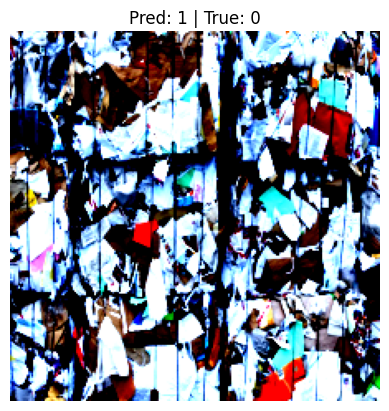

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


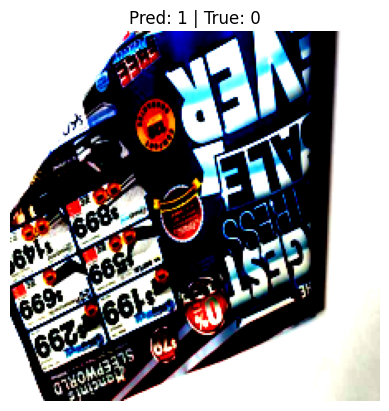

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3301654..2.64].


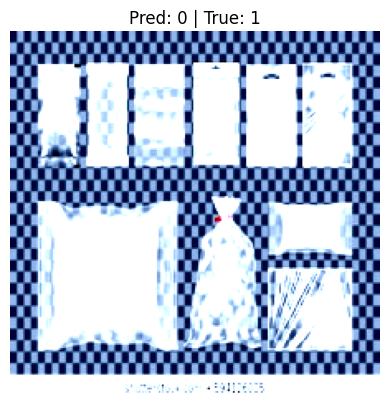

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9980307..2.64].


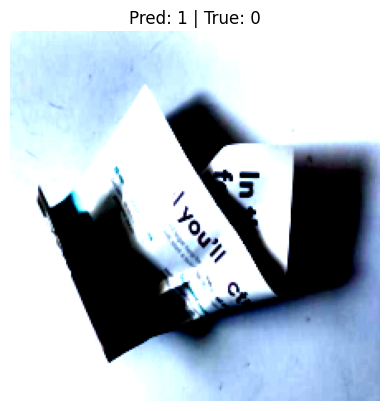

In [43]:
show_misclassified(model, val_loader, val_dataset)

## Test on New Data

### Step 1: Load the data

In [44]:
model.load_state_dict(torch.load("../models/best.pt"))
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### Step 2: Prediction Function

In [63]:
import torch.nn.functional as F

class_names = ["Biodegradable", "Non-Biodegradable"]

def show_prediction(image_path, true_label=None):
    img = Image.open(image_path).convert("RGB")
    
    # preprocess
    image = val_transforms(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(image)
        probs = F.softmax(outputs, dim=1)
        conf, pred = torch.max(probs, 1)
    
    prediction = class_names[pred.item()]
    confidence = conf.item() * 100
    
    plt.figure(figsize=(5,5))
    plt.imshow(img)
    
    if true_label:
        plt.title(f"Pred: {prediction} ({confidence:.2f}%)\nTrue: {true_label}")
    else:
        plt.title(f"Pred: {prediction} ({confidence:.2f}%)")
    
    plt.axis("off")
    plt.show()

### Step 3: Testing

In [64]:
def show_prediction(image_path):
    import os
    # Support running notebook from either project root or notebooks/ directory
    candidate_paths = [
        image_path,
        os.path.join("..", image_path)
    ]
    resolved_path = next((p for p in candidate_paths if os.path.exists(p)), None)
    if resolved_path is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    img = Image.open(resolved_path).convert("RGB")
    
    image = val_transforms(img).unsqueeze(0).to(device)
    with torch.no_grad():
        outputs = model(image)
        _, pred = torch.max(outputs, 1)
    class_names = ["Biodegradable", "Non-Biodegradable"]
    prediction = class_names[pred.item()]
    
    plt.imshow(img)
    plt.title(f"Prediction: {prediction}")
    plt.axis("off")
    plt.show()
    return prediction

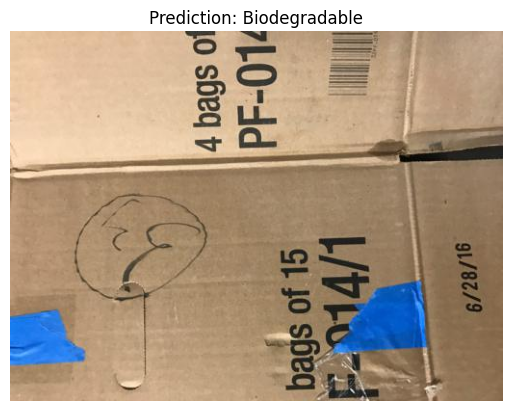

Prediction: Biodegradable
Used image: ../data/raw/train/biodegradable/paper_waste/cardboard66.jpg


In [65]:
import os

# Pick a real image from validation dataframe instead of hardcoded test path.
valid_paths = val_df[val_df['image_path'].apply(lambda p: isinstance(p, str) and os.path.exists(p))]['image_path']
if len(valid_paths) == 0:
    raise FileNotFoundError("No existing image files found in val_df['image_path']")

img_path = valid_paths.iloc[0]
result = show_prediction(img_path)
print("Prediction:", result)
print("Used image:", img_path)

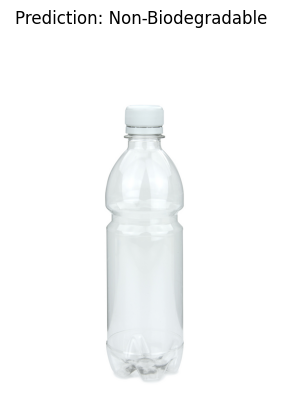

Prediction: Non-Biodegradable


In [66]:
img_path2 = "data/00000001.jpg"  

result = show_prediction(img_path2)
print("Prediction:", result)

In [67]:
def predict_image_with_conf(image_path, model):
    img = Image.open(image_path).convert("RGB")
    
    image = val_transforms(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(image)
        probs = torch.nn.functional.softmax(outputs, dim=1)
        conf, pred = torch.max(probs, 1)
    
    return class_names[pred.item()], conf.item()

In [68]:
label, conf = predict_image_with_conf(img_path, model)

print(f"Prediction: {label} ({conf*100:.2f}%)")

Prediction: Biodegradable (91.30%)


## Build Model: CNN

### Preprocessing for CNN
Transformations

In [75]:
from torchvision import transforms

cnn_train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    
    transforms.ToTensor()
])

cnn_val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

### Defining Dataset

In [76]:
train_dataset = WasteDataset(train_df, transform=cnn_train_transforms)
val_dataset = WasteDataset(val_df, transform=cnn_val_transforms)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

### Step 1: Build CNN

In [77]:
import torch.nn as nn
import torch.nn.functional as F

class WasteCNN(nn.Module):
    def __init__(self):
        super(WasteCNN, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        
        self.pool = nn.MaxPool2d(2, 2)
        
        self.fc1 = nn.Linear(256 * 14 * 14, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # 112
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # 56
        x = self.pool(F.relu(self.bn3(self.conv3(x))))   # 28
        x = self.pool(F.relu(self.bn4(self.conv4(x))))   # 14
        
        x = x.view(x.size(0), -1)
        
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

### Step 2: Initialize the Model

In [78]:
cnn_model = WasteCNN().to(device)

### Steo 3: Loss and Optimizer

In [79]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

### Step 4: Training

In [80]:
import os
os.makedirs("../models", exist_ok=True)

def train_cnn(model, train_loader, val_loader, epochs=10):
    
    best_val_acc = 0
    
    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        
        # TRAIN
        model.train()
        train_loss, correct = 0, 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
        
        train_acc = correct / len(train_loader.dataset)
        
        # VALIDATION
        model.eval()
        val_loss, correct = 0, 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
        
        val_acc = correct / len(val_loader.dataset)
        
        print(f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")
        
        # SAVE BEST MODEL
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), "../models/cnn_best.pt")
            print("✅ CNN Best model saved!")

In [81]:
train_cnn(cnn_model, train_loader, val_loader, epochs=10)


Epoch 1/10
Train Acc: 0.7456 | Val Acc: 0.8288
✅ CNN Best model saved!

Epoch 2/10
Train Acc: 0.8164 | Val Acc: 0.8412
✅ CNN Best model saved!

Epoch 3/10
Train Acc: 0.8632 | Val Acc: 0.8288

Epoch 4/10
Train Acc: 0.8794 | Val Acc: 0.9202
✅ CNN Best model saved!

Epoch 5/10
Train Acc: 0.8795 | Val Acc: 0.8496

Epoch 6/10
Train Acc: 0.8900 | Val Acc: 0.9192

Epoch 7/10
Train Acc: 0.8924 | Val Acc: 0.8909

Epoch 8/10
Train Acc: 0.8974 | Val Acc: 0.9273
✅ CNN Best model saved!

Epoch 9/10
Train Acc: 0.8993 | Val Acc: 0.9280
✅ CNN Best model saved!

Epoch 10/10
Train Acc: 0.9074 | Val Acc: 0.9170


### Step 5: Evaluation

In [82]:
cnn_model.load_state_dict(torch.load("../models/cnn_best.pt"))
cnn_model.eval()

y_true, y_pred = evaluate_model(cnn_model, val_loader)

print(classification_report(y_true, y_pred, target_names=["Bio", "Non-Bio"]))

              precision    recall  f1-score   support

         Bio       0.98      0.94      0.96      2540
     Non-Bio       0.61      0.83      0.71       293

    accuracy                           0.93      2833
   macro avg       0.80      0.89      0.83      2833
weighted avg       0.94      0.93      0.93      2833



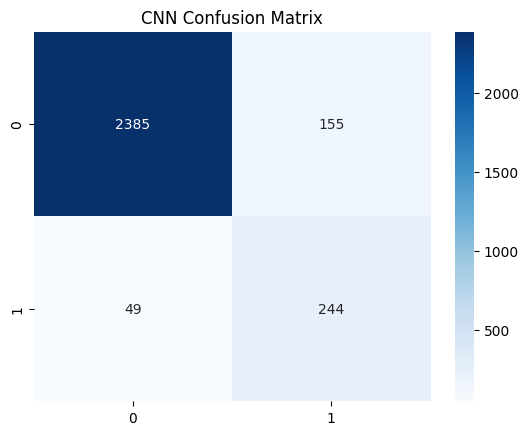

In [83]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("CNN Confusion Matrix")
plt.show()

### Step 6: Prediction

In [84]:
def predict_image_cnn(image_path, model):
    
    img = Image.open(image_path).convert("RGB")
    img = cnn_val_transforms(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        outputs = model(img)
        probs = torch.nn.functional.softmax(outputs, dim=1)
        conf, pred = torch.max(probs, 1)
    
    class_names = ["Biodegradable", "Non-Biodegradable"]
    
    return class_names[pred.item()], conf.item()

### Step 7: Testing on New Data

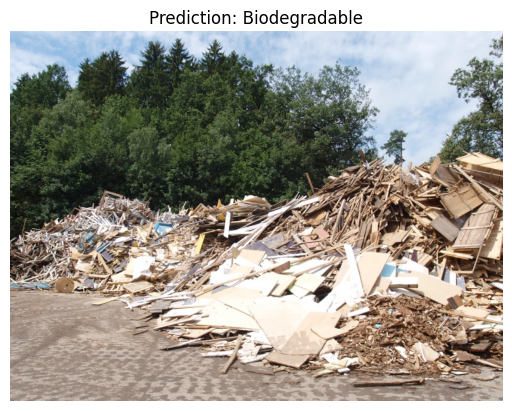

CNN Prediction: Biodegradable (67.58%)


In [86]:
img_path = "../data/test.jpg"

label, conf = predict_image_cnn(img_path, cnn_model)

result = show_prediction(img_path)
print(f"CNN Prediction: {label} ({conf*100:.2f}%)")